# 06 — Injection–Recovery, Parts A and B (SPARC only)

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

This notebook implements **proposal Section 4.6** for the population-dependence test of Notebook 05. Mock catalogues use SPARC's real radial sampling, velocity errors, baryonic components, catalogue nuisance values and galaxy properties. They are analysed with **exactly Notebook 05's model, priors and decision rule**.

* **Part A — false positives (essential).** The mocks follow **one universal RAR**, so no parameter depends on galaxy properties. How often does the Notebook 05 pipeline still call a slope "supported"?
  * **A1, correlated-noise null:** truth from the full Model D posterior of Notebook 04. Each galaxy has its own correlated-noise amplitude A_i and length ℓ_i (the posterior medians), plus τ and σ_int from Model D. This tests the specific alternative raised by Notebook 04: that galaxy-dependent correlated noise could *mimic* the Notebook 05 slopes.
  * **A2, white-noise null (calibration):** truth from Notebook 03's Model C, the model actually fitted. Its false-positive rate should match the nominal level.
  * From these come the null distribution of every slope, a **noise-calibrated significance** for each real Notebook 05 slope and the family-wise false-positive rate.
* **Part B — recovery.** Each covariate's slopes are injected at 0.5× and 1× the amplitudes measured in Notebook 05, on the white-noise base. This gives the bias, the 95% interval coverage and the detection power.
* **Not in this notebook:** Part C, the identifiability map of σ_int versus correlated noise (Sec. 4.3), which needs GP fits. Survey offsets are not applicable (SPARC only).

**Mock-fit sampler.** There are many mocks, so each uses 2 chains with 500 warmup and 750 draws (Notebook 05 used 4 × (1000 + 1500)). A mock fit counts as usable if the slopes and intercepts have R-hat < 1.05 and bulk ESS ≥ 100 and there are 0 divergences. The strict Notebook 05 verdict is recorded as well. Unusable fits are reported and excluded from the rates, never silently dropped.

**Runtime.** About 1.5–2 min per mock fit on Colab, roughly 2–2.5 h for the default plan. Each mock's results are written to Drive as soon as it finishes, and an interrupted run can be resumed (Section 2).

In [1]:
import os, logging
os.environ["RAR_RESUME_FROM"] = "/content/drive/MyDrive/RAR_Universality_Research/05_Results/Injection_Recovery/20261028T052341Z"
logging.raiseExceptions = False   # stops the harmless Drive log-warning spam

## 2. Environment and Configuration

In [2]:
import os, sys, importlib.util, subprocess
N_CPU = os.cpu_count() or 1
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={max(1, min(N_CPU, 8))}"
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.isdir("/kaggle/working")
REQUIRED = {"jax": "jax", "numpyro": "numpyro", "xarray": "xarray", "h5netcdf": "h5netcdf", "h5py": "h5py",
            "scipy": "scipy", "matplotlib": "matplotlib", "pandas": "pandas", "mpmath": "mpmath"}
missing = [p for m, p in REQUIRED.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import re, json, time, glob, hashlib, logging, platform, warnings, resource, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, scipy, scipy.stats as sst, xarray as xr
import matplotlib, matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from jax.scipy.linalg import cholesky as jcholesky, solve_triangular
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
from numpyro.infer.util import log_density, unconstrain_fn
from jax.scipy.special import ndtr, ndtri
from numpyro.diagnostics import split_gelman_rubin, effective_sample_size
numpyro.enable_x64()
numpyro.set_host_device_count(max(1, min(N_CPU, 8)))

RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
RUN_ID = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
            "jax": jax.__version__, "numpyro": numpyro.__version__, "xarray": xr.__version__, "matplotlib": matplotlib.__version__,
            "cpu_count": N_CPU, "jax_devices": len(jax.devices()), "jax_backend": jax.default_backend(), "x64": bool(jax.config.read("jax_enable_x64"))}
print(f"Run {RUN_ID} | Colab: {IN_COLAB}"); print(VERSIONS)

Run 20261028T075632Z | Colab: True
{'python': '3.13.18', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'jax': '0.11.1', 'numpyro': '0.22.0', 'xarray': '2025.12.0', 'matplotlib': '3.10.0', 'cpu_count': 2, 'jax_devices': 2, 'jax_backend': 'cpu', 'x64': True}


In [3]:
# =====================================================================
# CONFIGURATION
# =====================================================================
DRIVE_MOUNT_POINT = Path("/content/drive"); DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))
if IN_KAGGLE and "RAR_PROJECT_ROOT" not in os.environ:          # optional: also runs unattended on Kaggle
    import shutil
    cands = [p.parent for p in Path("/kaggle/input").rglob("03_Processed_Data") if p.is_dir()]
    full = [c for c in cands if any((c / "05_Results" / "Posterior_Samples").glob("03_bayesian_full_modelC_posterior*.nc"))]
    if not (full or cands): raise FileNotFoundError("Add your RAR_Universality_Research dataset as a Kaggle input.")
    src = sorted(full or cands, key=lambda p: len(p.parts))[0]
    PROJECT_ROOT = Path("/kaggle/working/RAR_Universality_Research")
    if not PROJECT_ROOT.exists(): shutil.copytree(src, PROJECT_ROOT, ignore=shutil.ignore_patterns("01_Datasets"))
PROC = PROJECT_ROOT / "03_Processed_Data"
DIRS = {"processed": PROC, "models": PROJECT_ROOT / "04_Trained_Models", "tables": PROJECT_ROOT / "05_Results" / "Tables",
        "posterior": PROJECT_ROOT / "05_Results" / "Posterior_Samples", "logs": PROC / "logs"}           # read-only inputs
NB02 = {"points": PROC / "sparc_rar_points_baseline.csv", "galaxies": PROC / "sparc_rar_galaxies_baseline.csv", "npz": PROC / "sparc_rar_model_inputs.npz"}
AUDIT01 = PROC / "sparc_galaxy_audit.csv"            # Notebook 01: derived Mbar and gas fraction (documented fiducial definitions)
NB03_RUN_ID = os.environ.get("RAR_NB03_RUN_ID", "")
OUT_ROOT = PROJECT_ROOT / "05_Results" / "Injection_Recovery" / RUN_ID         # new, versioned; never overwrites
NB04_DIR = PROJECT_ROOT / "05_Results" / "Diagnostics" / "04_GP_Debugged"          # read-only: full Model D posterior
NB05_DIR = PROJECT_ROOT / "05_Results" / "Population_Dependence"                   # read-only: real slopes
OUT = {k: OUT_ROOT / k for k in ("posterior", "tables", "figures", "diagnostics", "config", "logs")}

KPC_IN_M, KMS_IN_MS, LN10 = 3.0856775814913673e19, 1.0e3, float(np.log(10.0))
REF = {"a0": 1.20e-10, "beta": 0.5, "upsilon_disk": 0.5, "upsilon_bulge": 0.7}
UPS_SIGMA_DEX = {"D": 0.10, "E": 0.20}             # Model C uses the 0.10 dex width (verified against Notebook 03)

# ---------------- Population model (proposal Sec. 4.5) ----------------
COVARIATES = {   # name: (definition, source)
    "logMbar": ("log10 baryonic mass [Msun] = log10(1.33 M_HI + 0.5 L[3.6]); Notebook 01 fiducial definition", "sparc_galaxy_audit.csv"),
    "logSB0":  ("log10 central disk surface brightness at 3.6 um [Lsun/pc^2] (SPARC SBdisk)", "sparc_rar_galaxies_baseline.csv"),
    "fgas":    ("gas fraction 1.33 M_HI / Mbar (Notebook 01 fiducial definition)", "sparc_galaxy_audit.csv"),
}
POP_PARAMS = ["log10_a0", "beta", "log_sigma_int", "log_tau"]
# Slope priors (per 1 SD of the covariate). They are not specified by the proposal: weakly informative regularisation choices,
# with a x2 sensitivity test. The intercepts (values at the sample-mean property) keep Notebook 03's priors exactly.
SLOPE_PRIOR_SD = {"log10_a0": 0.25,      # dex of a0 per SD
                  "beta": 0.10,          # beta per SD
                  "log_sigma_int": 0.5,  # natural-log units per SD (x1.65 per SD at 1 sigma)
                  "log_tau": 0.5}
BETA_FLOOR = 0.01                         # beta_i <= floor is outside the RAR's domain (zero likelihood); reported if ever approached
FITS_ONE_AT_A_TIME = list(COVARIATES)     # primary analysis
RUN_JOINT_FIT = True                      # secondary analysis (all three covariates together)
# ---------------- Injection-recovery plan ----------------
N_NULL_CORR = int(os.environ.get("RAR_N_NULL_CORR", 16))     # Part A1: correlated-noise null mocks (x 3 one-at-a-time fits)
N_NULL_WHITE = int(os.environ.get("RAR_N_NULL_WHITE", 6))    # Part A2: white-noise calibration mocks (x 3 fits)
INJ_AMPLITUDES = [0.5, 1.0]                                  # Part B: fraction of the Notebook 05 slopes injected
N_INJ = int(os.environ.get("RAR_N_INJ", 2))                  # Part B: mocks per covariate and amplitude (1 fit each)
MOCK_SEED = 20261028
MOCK_FIT = {"chains": int(os.environ.get("RAR_MOCK_CHAINS", 2)), "warmup": int(os.environ.get("RAR_MOCK_WARMUP", 500)),
            "samples": int(os.environ.get("RAR_MOCK_SAMPLES", 750))}
MOCK_RHAT_MAX, MOCK_ESS_MIN = float(os.environ.get("RAR_MOCK_RHAT_MAX", 1.05)), float(os.environ.get("RAR_MOCK_ESS_MIN", 100))   # usability rule for mock fits (slopes, intercepts); env override for testing only
RESUME_FROM = os.environ.get("RAR_RESUME_FROM", "")          # path of an earlier 06 run folder to resume from ("" = fresh)
RUN_PRIOR_SENSITIVITY = False
FAMILY_ALPHA = 0.05                       # family-wise error rate over the declared test family (12 slopes)

# ---------------- Sampler (Notebook 03 settings; Model C converged with them) ----------------
SEED = 20261027
TARGET_ACCEPT, MAX_TREE_DEPTH = 0.90, 10
FIT = {"chains": int(os.environ.get("RAR_CHAINS", 4)), "warmup": int(os.environ.get("RAR_WARMUP", 1000)), "samples": int(os.environ.get("RAR_SAMPLES", 1500))}
RHAT_MAX, ESS_BULK_MIN, ESS_TAIL_MIN, DIVERGENCES_MAX, BFMI_MIN = 1.01, 400, 400, 0, 0.3
ILOO = {"post_draws": int(os.environ.get("RAR_ILOO_DRAWS", 300)), "mc": int(os.environ.get("RAR_ILOO_MC", 64))}
ALLOW_OVERWRITE = False
PROGRESS = not IN_KAGGLE
print("Project root:", PROJECT_ROOT); print("Outputs ->", OUT_ROOT)

Project root: /content/drive/MyDrive/RAR_Universality_Research
Outputs -> /content/drive/MyDrive/RAR_Universality_Research/05_Results/Injection_Recovery/20261028T075632Z


## 3. Drive, Logging and Notebook 03 Inputs

In [4]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
if OUT_ROOT.exists() and any(OUT_ROOT.iterdir()):
    raise FileExistsError(f"{OUT_ROOT} already exists and is not empty; refusing to overwrite")
for d in OUT.values():
    d.mkdir(parents=True, exist_ok=True)
LOG_PATH = OUT["logs"] / f"06_injection_{RUN_ID}.log"
logger = logging.getLogger("rar06"); logger.setLevel(logging.INFO); logger.handlers.clear(); logger.propagate = False
_fh = logging.FileHandler(LOG_PATH, encoding="utf-8"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status, "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(f"[{status}] {section} | {name} | {detail}")
    if status == "FAIL":
        raise RuntimeError(f"Critical check failed: {section} | {name} | {detail}")
    return bool(passed)

def safe_path(path: Path) -> Path:
    if path.exists() and not ALLOW_OVERWRITE:
        new = path.with_name(f"{path.stem}_{RUN_ID}{path.suffix}"); logger.info(f"{path.name} exists; writing {new.name}"); return new
    return path

def sha256_of(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()
print("Log:", LOG_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Log: /content/drive/MyDrive/RAR_Universality_Research/05_Results/Injection_Recovery/20261028T075632Z/logs/06_injection_20261028T075632Z.log


In [5]:
cfgs = []
for p in sorted(DIRS["models"].glob("03_bayesian_sampler_config*.json")):
    try:
        c = json.loads(p.read_text()); cm = c.get("full", {}).get("completed_models", {})
        cfgs.append({"file": p.name, "run_id": c.get("run_id"), "created": c.get("created_utc"), "full_models": ",".join(cm), "cfg": c})
    except Exception as exc:
        logger.warning(f"Could not read {p.name}: {exc}")
cfg_table = pd.DataFrame(cfgs)
display(cfg_table.drop(columns="cfg") if len(cfg_table) else "no Notebook 03 configurations found")
cands = [c for c in cfgs if "C" in c["full_models"].split(",") and (not NB03_RUN_ID or c["run_id"] == NB03_RUN_ID)]
record_check("NB03", "a Notebook 03 run with a completed full Model C exists", bool(cands), f"{len(cands)} candidate runs")
nb03 = max(cands, key=lambda c: c["created"]); CFG03 = nb03["cfg"]; RUN03 = nb03["run_id"]
print(f"Using Notebook 03 run {RUN03} (config {nb03['file']})")

def run_file(folder, stem, ext):
    # File written by run RUN03: suffixed name if present, else the base name.
    p1 = folder / f"{stem}_{RUN03}{ext}"; p0 = folder / f"{stem}{ext}"
    return p1 if p1.is_file() else p0

NC03 = {}
for m, info in CFG03["full"]["completed_models"].items():
    p = Path(info["netcdf"])
    if not p.is_file():                                         # stored path may be absolute from another mount; fall back to folder
        p = DIRS["posterior"] / Path(info["netcdf"]).name
    record_check("NB03", f"Model {m} posterior file exists", p.is_file(), str(p))
    attrs = xr.open_dataset(p, group="posterior", engine="h5netcdf").attrs
    record_check("NB03", f"Model {m} posterior carries run ID {RUN03}", attrs.get("run_id") == RUN03, f"file run_id {attrs.get('run_id')}")
    st = info["stats"]
    record_check("NB03", f"Model {m} met all convergence criteria in Notebook 03", bool(st["converged_by_all_criteria"]),
                 f"max R-hat {st['max_r_hat_all']:.4f}, min ESS {st['min_ess_bulk_all']:.0f}, divergences {st['divergences']}",
                 severity="warning" if os.environ.get("RAR_TEST_ALLOW_UNCONVERGED_NB03") == "1" else "critical")   # override: local testing only
    NC03[m] = p
chk03_path = run_file(DIRS["processed"], "03_bayesian_integrity_checks", ".csv")
chk03 = pd.read_csv(chk03_path)
record_check("NB03", "Notebook 03 check register has no FAIL rows", int((chk03.status == "FAIL").sum()) == 0,
             f"{chk03_path.name}: {len(chk03)} checks, {int((chk03.status=='FAIL').sum())} FAIL, {int((chk03.status=='WARN').sum())} WARN")
print("Notebook 03 warnings:"); display(chk03[chk03.status == "WARN"][["section", "check", "detail"]])
comp03_path = run_file(DIRS["tables"], "03_bayesian_model_comparison", ".csv")
comp03 = pd.read_csv(comp03_path) if comp03_path.is_file() else pd.DataFrame()
if len(comp03):
    display(comp03[[c for c in comp03.columns if c in ("stage", "model", "elpd_loo_galaxy", "p_loo", "n_pareto_k_gt_0.7", "sigma_int_median", "tau_median")]])
    bad_k = comp03[(comp03.get("n_pareto_k_gt_0.7", 0) > 0.1 * comp03.get("n_galaxies", 1))]
    record_check("NB03", "Notebook 03 galaxy-level PSIS-LOO reliable (Pareto k > 0.7 in < 10% of galaxies)", bad_k.empty,
                 bad_k[["stage", "model", "n_pareto_k_gt_0.7"]].values.tolist() if not bad_k.empty else "ok", severity="warning")

# Shared priors must be identical to Notebook 03
P03 = CFG03["priors"]
same_priors = (P03["log10_a0"]["low"] == -11.5 and P03["log10_a0"]["high"] == -8.5 and P03["beta"]["low"] == 0.05 and P03["beta"]["high"] == 1.0
               and P03["sigma_int"]["scale"] == 0.1 and P03["tau"]["scale"] == 0.1 and P03["upsilon_disk"]["sigma_dex"] == UPS_SIGMA_DEX["D"]
               and P03["upsilon_disk"]["median"] == REF["upsilon_disk"] and P03["upsilon_bulge"]["median"] == REF["upsilon_bulge"]
               and P03["inclination"]["low"] == 1.0 and P03["inclination"]["high"] == 90.0)
record_check("NB03", "shared priors in this notebook equal Notebook 03's saved priors", same_priors, "log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds")
record_check("NB03", "Sigma_x convention unchanged (0: no documented baryonic-component errors)", CFG03.get("sigma_x_log_gbar", None) == 0.0, "0.0")

,file,run_id,created,full_models
0,03_bayesian_sampler_config.json,20261022T095219Z,2026-10-22T09:52:19Z,
1,03_bayesian_sampler_config_20261022T095735Z.json,20261022T095735Z,2026-10-22T09:57:35Z,"C,A,B"


INFO: [PASS] NB03 | a Notebook 03 run with a completed full Model C exists | 1 candidate runs
Using Notebook 03 run 20261022T095735Z (config 03_bayesian_sampler_config_20261022T095735Z.json)
INFO: [PASS] NB03 | Model C posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelC_posterior.nc
INFO: [PASS] NB03 | Model C posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model C met all convergence criteria in Notebook 03 | max R-hat 1.0014, min ESS 2962, divergences 0
INFO: [PASS] NB03 | Model A posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelA_posterior.nc
INFO: [PASS] NB03 | Model A posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model A met all convergence criteria in Notebook 03 | max R-hat 1.0026, min ESS 1913, divergences 0
INFO: [PASS] NB03 | Model B poste

,section,check,detail
17,Positivity,every point excluded by the rule was also non-...,"rule excludes [('DDO064', 0), ('UGC01281', 0),..."


,stage,model,elpd_loo_galaxy,p_loo,n_pareto_k_gt_0.7,sigma_int_median,tau_median
0,PILOT (validation only),C,135.761034,58.684227,5,0.060355,0.186125
1,FULL,A,3084.192629,47.431458,3,0.057298,0.155636
2,FULL,B,3151.837121,64.228407,4,0.045952,0.147108
3,FULL,C,3661.801975,379.460001,88,0.035569,0.121956


INFO: [PASS] NB03 | shared priors in this notebook equal Notebook 03's saved priors | log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds
INFO: [PASS] NB03 | Sigma_x convention unchanged (0: no documented baryonic-component errors) | 0.0


True

In [6]:
for k in ("points", "galaxies", "npz"):
    rec = CFG03["input_checksums"].get(NB02[k].name)
    record_check("Sample", f"{NB02[k].name} unchanged since Notebook 03", rec is not None and sha256_of(NB02[k]) == rec, "SHA-256 compared")
pts = pd.read_csv(NB02["points"]); gals = pd.read_csv(NB02["galaxies"])
npz = np.load(NB02["npz"])
p_sorted = pts.sort_values(["galaxy_index", "point_index"]).reset_index(drop=True)
gtab = gals.sort_values("galaxy_index").reset_index(drop=True)
G = len(gtab); gi = p_sorted.galaxy_index.to_numpy(np.int32)
R0, V0, eV0 = npz["R_kpc"], npz["Vobs_kms"], npz["errV_kms"]
Vg0, Vd0, Vb0 = npz["Vgas_kms"], npz["Vdisk_ups1_kms"], npz["Vbul_ups1_kms"]
D0, eD0 = gtab.distance_mpc.to_numpy(float), gtab.e_distance_mpc.to_numpy(float)
I0, eI0 = gtab.inc_deg.to_numpy(float), gtab.e_inc_deg.to_numpy(float)
has_bulge = p_sorted.groupby("galaxy_index").Vbul.apply(lambda s: bool((s > 0).any())).reindex(range(G)).to_numpy()

# Positivity rule exactly as Notebook 03 (same seed and draw count); E's wider prior is evaluated for information only
def positivity(sig_dex, seed, n):
    rng = np.random.default_rng(seed)
    ud = 10 ** (np.log10(REF["upsilon_disk"]) + sig_dex * rng.standard_normal(n))
    ub = 10 ** (np.log10(REF["upsilon_bulge"]) + sig_dex * rng.standard_normal(n))
    p = np.ones(len(R0))
    for k in np.where(Vg0 <= 0)[0]:
        p[k] = float(np.mean(ud * Vd0[k] ** 2 + ub * Vb0[k] ** 2 + Vg0[k] * abs(Vg0[k]) > 0))
    return p
pos = CFG03["positivity_rule"]
p_pos = positivity(UPS_SIGMA_DEX["D"], CFG03["seed"], pos["mc_draws"])
gbar_ref = (Vg0 * np.abs(Vg0) + 0.5 * Vd0 ** 2 + 0.7 * Vb0 ** 2)
include = (p_pos >= pos["P_prior_min"]) & (gbar_ref > 0)
excl = sorted(zip(p_sorted.galaxy[~include], p_sorted.point_index[~include].astype(int)))
record_check("Sample", f"point set reproduces Notebook 03 ({pos['n_points_included']} points)", int(include.sum()) == pos["n_points_included"], f"{int(include.sum())}")
record_check("Sample", "excluded points identical to Notebook 03", [list(map(lambda v: v if isinstance(v, str) else int(v), e)) for e in excl] == pos["excluded_points"], excl)


INFO: [PASS] Sample | sparc_rar_points_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_galaxies_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_model_inputs.npz unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | point set reproduces Notebook 03 (3164 points) | 3164
INFO: [PASS] Sample | excluded points identical to Notebook 03 | [('DDO064', 0), ('UGC01281', 0), ('UGC01281', 1), ('UGC07577', 0)]


True

## 4. Covariates, Likelihood and Model (identical to Notebook 05)

In [7]:
aud = pd.read_csv(AUDIT01)
cov = gtab[["galaxy", "galaxy_index", "SBdisk0_Lsun_pc2"]].merge(aud[["galaxy", "Mbar_1e9Msun_derived_fid", "fgas_derived_fid", "MHI_1e9Msun", "L36_1e9Lsun"]], on="galaxy", how="left")
cov["logMbar"] = np.log10(cov.Mbar_1e9Msun_derived_fid * 1e9)
cov["logSB0"] = np.log10(cov.SBdisk0_Lsun_pc2)
cov["fgas"] = cov.fgas_derived_fid
recheck = np.allclose(cov.Mbar_1e9Msun_derived_fid, 1.33 * cov.MHI_1e9Msun + 0.5 * cov.L36_1e9Lsun, rtol=1e-6)
record_check("Covariates", "Mbar reproduces 1.33 M_HI + 0.5 L[3.6] (Notebook 01 definition)", recheck, "")
record_check("Covariates", "galaxy order equals the model-input order", list(cov.galaxy_index) == list(range(G)), f"{G} galaxies")
for c in COVARIATES:
    record_check("Covariates", f"{c} finite for all {G} galaxies", bool(np.isfinite(cov[c]).all()), f"{int((~np.isfinite(cov[c])).sum())} non-finite")
COV_MEAN = {c: float(cov[c].mean()) for c in COVARIATES}; COV_SD = {c: float(cov[c].std(ddof=0)) for c in COVARIATES}
Zall = np.column_stack([(cov[c] - COV_MEAN[c]) / COV_SD[c] for c in COVARIATES])
cov_corr = pd.DataFrame(np.corrcoef(Zall.T), index=list(COVARIATES), columns=list(COVARIATES))
vif = {c: float(np.linalg.inv(cov_corr.values)[k, k]) for k, c in enumerate(COVARIATES)}
print("Covariate summary (physical units):"); display(cov[list(COVARIATES)].describe().T)
print("Correlation matrix of the standardised covariates:"); display(cov_corr.round(3))
print("Variance inflation factors (joint fit):", {k: round(v, 2) for k, v in vif.items()})
if max(vif.values()) > 2.5:
    logger.warning("Covariates are strongly correlated: joint-fit slopes will be partly degenerate. The one-at-a-time fits are primary (declared).")
cov_table = cov[["galaxy", "logMbar", "logSB0", "fgas"]].assign(**{f"z_{c}": Zall[:, k] for k, c in enumerate(COVARIATES)})

INFO: [PASS] Covariates | Mbar reproduces 1.33 M_HI + 0.5 L[3.6] (Notebook 01 definition) | 
INFO: [PASS] Covariates | galaxy order equals the model-input order | 153 galaxies
INFO: [PASS] Covariates | logMbar finite for all 153 galaxies | 0 non-finite
INFO: [PASS] Covariates | logSB0 finite for all 153 galaxies | 0 non-finite
INFO: [PASS] Covariates | fgas finite for all 153 galaxies | 0 non-finite
Covariate summary (physical units):


,count,mean,std,min,25%,50%,75%,max
logMbar,153.0,9.827318,0.949282,7.690728,9.215529,9.785799,10.663295,11.429540
logSB0,153.0,2.642165,0.689011,1.324899,2.060849,2.592832,3.172831,4.376830
fgas,153.0,0.449970,0.271471,0.015500,0.185615,0.443737,0.678258,0.945325


Correlation matrix of the standardised covariates:


,logMbar,logSB0,fgas
logMbar,1.000,0.659,-0.769
logSB0,0.659,1.000,-0.742
fgas,-0.769,-0.742,1.000


Variance inflation factors (joint fit): {'logMbar': 2.56, 'logSB0': 2.32, 'fgas': 3.21}


In [8]:
def accelerations(D, inc_deg, ups_d, ups_b, idx, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=jnp):
    sD = (D / D0)[idx]
    s_inc = (xp.sin(xp.deg2rad(I0)) / xp.sin(xp.deg2rad(inc_deg)))[idx]
    R_m = R0 * sD * KPC_IN_M
    Vobs, eV = V0 * s_inc, eV0 * s_inc
    vbar2 = (Vg0 * xp.abs(Vg0) + ups_d[idx] * Vd0 ** 2 + ups_b[idx] * Vb0 ** 2) * sD
    g_obs = (Vobs * KMS_IN_MS) ** 2 / R_m
    g_bar = vbar2 * KMS_IN_MS ** 2 / R_m
    sig_V = 2.0 * eV / (Vobs * LN10)
    return g_obs, g_bar, sig_V

def f_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return x - jnp.log10(-jnp.expm1(-t))

def fprime_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return 1.0 - beta * t * jnp.exp(-t) / (-jnp.expm1(-t))

def residual_terms(params, data, nuis):
    log10_a0, beta = params[0], params[1]
    D, inc, ud, ub = nuis
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, data["idx"], data["R0"], data["V0"], data["eV0"],
                                        data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    mu = f_rar(x, log10_a0, beta)
    return y - mu, sig_V, x, y, mu, pos

def galaxy_loglik_C(params, data, nuis):
    # Notebook 03 Model C likelihood (Sherman-Morrison, delta_i marginalised).
    log10_a0, beta, sig_int, tau, s = params
    r, sig_V, x, _, _, pos = residual_terms(params, data, nuis)
    d = (s * sig_V) ** 2 + (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2 + sig_int ** 2
    seg = lambda v: jax.ops.segment_sum(v, data["idx"], num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - tau ** 2 * A ** 2 / (1 + tau ** 2 * S) + L + jnp.log1p(tau ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

def build_data_C(mask_points):
    rows = np.where(np.asarray(mask_points, bool))[0]
    gal_ids = np.unique(gi[rows]); remap = -np.ones(G, int); remap[gal_ids] = np.arange(len(gal_ids))
    idx = remap[gi[rows]]; Gs = len(gal_ids); bulge_local = np.where(has_bulge[gal_ids])[0]
    return {"idx": jnp.asarray(idx), "G": Gs, "gal_ids": gal_ids, "rows": rows, "bulge_local": jnp.asarray(bulge_local), "n_bulge": len(bulge_local),
            **{k: jnp.asarray(v[rows]) for k, v in dict(R0=R0, V0=V0, eV0=eV0, Vg0=Vg0, Vd0=Vd0, Vb0=Vb0).items()},
            "D0": jnp.asarray(D0[gal_ids]), "eD0": jnp.asarray(eD0[gal_ids]), "I0": jnp.asarray(I0[gal_ids]), "eI0": jnp.asarray(eI0[gal_ids]),
            "sigx": jnp.zeros(len(rows))}

def galaxy_loglik_pop(a_g, b_g, s_g, t_g, data, nuis):
    # Model C likelihood with per-galaxy log10 a0, beta, sigma_int, tau (arrays of length G).
    D, inc, ud, ub = nuis; idx = data["idx"]
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, idx, data["R0"], data["V0"], data["eV0"], data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    a_p, b_p = a_g[idx], b_g[idx]
    r = y - f_rar(x, a_p, b_p)
    d = sig_V ** 2 + (fprime_rar(x, a_p, b_p) * data["sigx"]) ** 2 + s_g[idx] ** 2
    seg = lambda v: jax.ops.segment_sum(v, idx, num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - t_g ** 2 * A ** 2 / (1 + t_g ** 2 * S) + L + jnp.log1p(t_g ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

include_mask = include
data_full = build_data_C(include_mask)
Z_full = jnp.asarray(Zall[data_full["gal_ids"]])
print(f"Data: {data_full['G']} galaxies, {len(data_full['rows'])} points")

Data: 153 galaxies, 3164 points


In [9]:
ds_post = xr.open_dataset(NC03["C"], group="posterior", engine="h5netcdf")
ds_ll = xr.open_dataset(NC03["C"], group="log_likelihood", engine="h5netcdf")
names_nc = [str(x) for x in ds_post.galaxy.values]; names_here = list(gtab.galaxy.to_numpy()[data_full["gal_ids"]])
record_check("Regression", "Notebook 03 Model C galaxy order equals this notebook's", names_nc == names_here, f"{len(names_nc)} galaxies")
bulge_pos = [names_here.index(str(n)) for n in ds_post.bulge_galaxy.values] if "bulge_galaxy" in ds_post.dims else []
def nuis_from_nc(ds, c, d):
    ub = np.full(data_full["G"], REF["upsilon_bulge"])
    if bulge_pos: ub[bulge_pos] = ds["ups_bulge"].values[c, d]
    return (jnp.asarray(ds["D"].values[c, d]), jnp.asarray(ds["inc"].values[c, d]), jnp.asarray(ds["ups_disk"].values[c, d]), jnp.asarray(ub))
rng = np.random.default_rng(SEED); nchain, ndraw = ds_post.sizes["chain"], ds_post.sizes["draw"]; dev_saved, dev_C = 0.0, 0.0
for _ in range(10):
    c, d = int(rng.integers(nchain)), int(rng.integers(ndraw))
    th = [float(ds_post[k].values[c, d]) for k in ("log10_a0", "beta", "sigma_int", "tau")]
    nuis = nuis_from_nc(ds_post, c, d); Gn = data_full["G"]
    ll_p, _ = galaxy_loglik_pop(*(jnp.full(Gn, v) for v in th), data_full, nuis)
    ll_c, _ = galaxy_loglik_C((*th, 1.0), data_full, nuis)
    dev_saved = max(dev_saved, float(np.max(np.abs(np.asarray(ll_p) - ds_ll["galaxy_loglik"].values[c, d]))))
    dev_C = max(dev_C, float(np.max(np.abs(np.asarray(ll_p) - np.asarray(ll_c)))))
record_check("Regression", "zero-slope likelihood = Notebook 03 saved Model C log-likelihoods (10 draws, all galaxies)", dev_saved < 1e-6, f"max |diff| = {dev_saved:.2e}")
record_check("Regression", "zero-slope likelihood = Notebook 03 galaxy_loglik_C", dev_C < 1e-8, f"max |diff| = {dev_C:.2e}")
REGRESSION = {"max_abs_diff_vs_saved_NB03": dev_saved, "max_abs_diff_vs_C": dev_C}

INFO: [PASS] Regression | Notebook 03 Model C galaxy order equals this notebook's | 153 galaxies
INFO: [PASS] Regression | zero-slope likelihood = Notebook 03 saved Model C log-likelihoods (10 draws, all galaxies) | max |diff| = 2.37e-12
INFO: [PASS] Regression | zero-slope likelihood = Notebook 03 galaxy_loglik_C | max |diff| = 0.00e+00


In [10]:
PRIORS_SHARED = {"log10_a0": P03["log10_a0"], "beta": P03["beta"], "sigma_int": P03["sigma_int"], "tau": P03["tau"]}
def pop_model(data, cfg):
    Z = cfg["Z"]; K = Z.shape[1]; mult = cfg.get("slope_prior_mult", 1.0)
    log10_a0 = numpyro.sample("log10_a0", dist.Uniform(P03["log10_a0"]["low"], P03["log10_a0"]["high"]))
    beta = numpyro.sample("beta", dist.Uniform(P03["beta"]["low"], P03["beta"]["high"]))
    sig_int = numpyro.sample("sigma_int", dist.HalfNormal(P03["sigma_int"]["scale"]))
    tau = numpyro.sample("tau", dist.HalfNormal(P03["tau"]["scale"]))
    if K:
        s = {p: numpyro.sample(f"slope_{p}", dist.Normal(jnp.zeros(K), mult * SLOPE_PRIOR_SD[p]).to_event(1)) for p in POP_PARAMS}
        a_g = log10_a0 + Z @ s["log10_a0"]; b_g = beta + Z @ s["beta"]
        s_g = sig_int * jnp.exp(Z @ s["log_sigma_int"]); t_g = tau * jnp.exp(Z @ s["log_tau"])
    else:
        Gn = data["G"]; a_g, b_g, s_g, t_g = (jnp.full(Gn, log10_a0), jnp.full(Gn, beta), jnp.full(Gn, sig_int), jnp.full(Gn, tau))
    with numpyro.plate("galaxies", data["G"]):                       # Notebook 03 Model C nuisance sampling, verbatim
        zD = numpyro.sample("zD", dist.Normal(0, 1))
        inc = numpyro.sample("inc", dist.TruncatedNormal(data["I0"], data["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]))
        zUd = numpyro.sample("zUd", dist.Normal(0, 1))
    D = numpyro.deterministic("D", data["D0"] * jnp.exp(zD * data["eD0"] / data["D0"]))
    ud = numpyro.deterministic("ups_disk", P03["upsilon_disk"]["median"] * 10 ** (P03["upsilon_disk"]["sigma_dex"] * zUd))
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"] > 0:
        with numpyro.plate("bulge_galaxies", data["n_bulge"]):
            zUb = numpyro.sample("zUb", dist.Normal(0, 1))
        ub = ub.at[data["bulge_local"]].set(P03["upsilon_bulge"]["median"] * 10 ** (P03["upsilon_bulge"]["sigma_dex"] * zUb))
        numpyro.deterministic("ups_bulge", ub[data["bulge_local"]])
    numpyro.deterministic("beta_min_over_galaxies", jnp.min(b_g))
    ll, ok = galaxy_loglik_pop(a_g, b_g, s_g, t_g, data, (D, inc, ud, ub))
    numpyro.factor("loglik", jnp.where(ok & (jnp.min(b_g) > BETA_FLOOR), jnp.sum(ll), -jnp.inf))

def fit_cfg(name, covs, mult=1.0):
    k = [list(COVARIATES).index(c) for c in covs]
    return {"name": name, "covariates": list(covs), "Z": Z_full[:, k] if k else jnp.zeros((data_full["G"], 0)), "slope_prior_mult": mult}

C_MED = {k: float(np.median(ds_post[k].values)) for k in ("log10_a0", "beta", "sigma_int", "tau")}
def init_values(cfg):
    v = {**C_MED, "zD": jnp.zeros(data_full["G"]), "inc": jnp.clip(data_full["I0"], 2.0, 89.5), "zUd": jnp.zeros(data_full["G"])}
    if data_full["n_bulge"]: v["zUb"] = jnp.zeros(data_full["n_bulge"])
    for p in POP_PARAMS:
        if cfg["Z"].shape[1]: v[f"slope_{p}"] = jnp.zeros(cfg["Z"].shape[1])
    return v

from numpyro.infer.util import log_density
lp0, _ = log_density(pop_model, (data_full, fit_cfg("baseline", [])), {}, init_values(fit_cfg("baseline", [])))
record_check("Model", "baseline (no slopes) log density finite at the initial values", bool(np.isfinite(float(lp0))), f"{float(lp0):.2f}")
cfg_test = fit_cfg("joint", list(COVARIATES)); iv = init_values(cfg_test)
lpj, trj = log_density(pop_model, (data_full, cfg_test), {}, iv)
lpb, trb = log_density(pop_model, (data_full, fit_cfg("baseline", [])), {}, init_values(fit_cfg("baseline", [])))
record_check("Model", "zero slopes give the baseline likelihood exactly", abs(float(trj["loglik"]["fn"].log_factor) - float(trb["loglik"]["fn"].log_factor)) < 1e-9, "joint vs baseline loglik factor")

INFO: [PASS] Model | baseline (no slopes) log density finite at the initial values | 2037.50
INFO: [PASS] Model | zero slopes give the baseline likelihood exactly | joint vs baseline loglik factor


True

In [11]:
def run_fit(cfg, seed):
    kernel = NUTS(pop_model, target_accept_prob=TARGET_ACCEPT, max_tree_depth=MAX_TREE_DEPTH, init_strategy=init_to_value(values=init_values(cfg)))
    method = "parallel" if len(jax.devices()) >= FIT["chains"] else "sequential"
    mcmc = MCMC(kernel, num_warmup=FIT["warmup"], num_samples=FIT["samples"], num_chains=FIT["chains"], chain_method=method, progress_bar=PROGRESS)
    t0 = time.time()
    mcmc.run(jax.random.PRNGKey(seed), data_full, cfg, extra_fields=("diverging", "num_steps", "energy", "accept_prob"))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, time.time() - t0

def _rank_norm(x):
    r = sst.rankdata(x.ravel()).reshape(x.shape); return sst.norm.ppf((r - 3 / 8) / (x.size + 1 / 4))
def rank_rhat(x):
    return max(float(split_gelman_rubin(_rank_norm(x)[..., None])[0]), float(split_gelman_rubin(_rank_norm(np.abs(x - np.median(x)))[..., None])[0]))
def bulk_ess(x): return float(effective_sample_size(_rank_norm(x)[..., None])[0])
def tail_ess(x):
    q05, q95 = np.quantile(x, [0.05, 0.95])
    return float(min(effective_sample_size((x <= q05).astype(float)[..., None])[0], effective_sample_size((x >= q95).astype(float)[..., None])[0]))
SAMPLED = ["log10_a0", "beta", "sigma_int", "tau", "zD", "inc", "zUd", "zUb"] + [f"slope_{p}" for p in POP_PARAMS]
def diagnostics(mcmc):
    smp = mcmc.get_samples(group_by_chain=True); rows = []
    for k in SAMPLED:
        if k not in smp: continue
        v = np.asarray(smp[k]); flat = v.reshape(v.shape[0], v.shape[1], -1)
        rh = [rank_rhat(flat[..., j]) for j in range(flat.shape[2])]; eb = [bulk_ess(flat[..., j]) for j in range(flat.shape[2])]
        et = [tail_ess(flat[..., j]) for j in range(flat.shape[2])]
        rows.append({"parameter": k, "n_elements": flat.shape[2], "max_r_hat": max(rh), "min_ess_bulk": min(eb), "min_ess_tail": min(et)})
    dg = pd.DataFrame(rows); ex = mcmc.get_extra_fields(group_by_chain=True)
    div = np.asarray(ex["diverging"]); steps = np.asarray(ex["num_steps"]); en = np.asarray(ex["energy"])
    st = {"divergences": int(div.sum()), "divergences_per_chain": div.sum(1).tolist(), "max_tree_depth_hits": int((steps >= 2 ** MAX_TREE_DEPTH - 1).sum()),
          "mean_accept_prob": float(np.asarray(ex["accept_prob"]).mean()), "bfmi_per_chain": [float(np.mean(np.diff(e) ** 2) / np.var(e)) for e in en],
          "max_r_hat_all": float(dg.max_r_hat.max()), "min_ess_bulk_all": float(dg.min_ess_bulk.min()), "min_ess_tail_all": float(dg.min_ess_tail.min())}
    st["converged_by_all_criteria"] = bool(st["max_r_hat_all"] < RHAT_MAX and st["min_ess_bulk_all"] >= ESS_BULK_MIN and st["min_ess_tail_all"] >= ESS_TAIL_MIN
                                           and st["divergences"] <= DIVERGENCES_MAX and st["max_tree_depth_hits"] == 0 and min(st["bfmi_per_chain"]) >= BFMI_MIN)
    return dg, st

def save_fit(mcmc, cfg, path):
    smp = mcmc.get_samples(group_by_chain=True); ex = mcmc.get_extra_fields(group_by_chain=True)
    C_, S_ = np.asarray(smp["log10_a0"]).shape; names = gtab.galaxy.to_numpy()[data_full["gal_ids"]].astype(str)
    post, coords = {}, {"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": names, "covariate": cfg["covariates"]}
    if data_full["n_bulge"]: coords["bulge_galaxy"] = names[np.asarray(data_full["bulge_local"])]
    for k, v in smp.items():
        v = np.asarray(v)
        if v.ndim == 2: post[k] = (("chain", "draw"), v)
        elif k.startswith("slope_"): post[k] = (("chain", "draw", "covariate"), v)
        elif v.shape[2] == data_full["G"]: post[k] = (("chain", "draw", "galaxy"), v)
        elif v.shape[2] == data_full["n_bulge"]: post[k] = (("chain", "draw", "bulge_galaxy"), v)
    if not cfg["covariates"]: coords.pop("covariate")
    path = safe_path(path)
    attrs = {"run_id": RUN_ID, "fit": cfg["name"], "covariates": json.dumps(cfg["covariates"]), "slope_prior_mult": cfg["slope_prior_mult"],
             "covariate_mean": json.dumps(COV_MEAN), "covariate_sd": json.dumps(COV_SD), "notebook03_run": RUN03}
    xr.Dataset(post, coords=coords, attrs=attrs).to_netcdf(path, group="posterior", mode="w", engine="h5netcdf")
    xr.Dataset({k2: (("chain", "draw"), np.asarray(ex[k1])) for k1, k2 in (("diverging", "diverging"), ("num_steps", "n_steps"), ("energy", "energy"), ("accept_prob", "acceptance_rate"))},
               coords={"chain": np.arange(C_), "draw": np.arange(S_)}).to_netcdf(path, group="sample_stats", mode="a", engine="h5netcdf")
    return path

## 5. Inputs from Notebooks 04 and 05 (read-only)

* **Notebook 04:** the latest debugged run that contains a full Model D posterior. The per-galaxy posterior medians of A_i and ℓ_i, plus the medians of log₁₀ a₀, β, τ and σ_int, define the A1 truth. Model D was not formally converged for one galaxy (UGC00128) and for τ and μ_u, so the A1 truth uses **medians only**. It is a realistic noise model, not a measurement.
* **Notebook 05:** the latest run's slopes from the one-at-a-time fits. These are the real values that the null distributions are compared against, and that Part B injects.

In [12]:
cands = sorted(NB04_DIR.glob("*/posterior/04d_gp_full_model_D_posterior*.nc"))
record_check("Inputs", "Notebook 04 full Model D posterior found", bool(cands), str(cands[-1]) if cands else f"none under {NB04_DIR}")
D_NC = cands[-1]
dpost = xr.open_dataset(D_NC, group="posterior", engine="h5netcdf")
names_D = [str(n) for n in dpost.galaxy.values]
record_check("Inputs", "Model D galaxy order equals this notebook's", names_D == names_here, f"{len(names_D)} galaxies")
TRUTH_CORR = {k: float(np.median(dpost[k].values)) for k in ("log10_a0", "beta", "tau", "sigma_int")}
A_TRUE = np.median(dpost["A"].values.reshape(-1, len(names_D)), axis=0); ELL_TRUE = np.median(dpost["ell"].values.reshape(-1, len(names_D)), axis=0)
TRUTH_WHITE = {k: float(np.median(ds_post[k].values)) for k in ("log10_a0", "beta", "tau", "sigma_int")}
print("A1 truth (Model D medians):", {k: round(v, 4) for k, v in TRUTH_CORR.items()}, "| A_i median", round(float(np.median(A_TRUE)), 2), "km/s; l_i median", round(float(np.median(ELL_TRUE)), 2), "kpc")
print("A2/B truth (NB03 Model C medians):", {k: round(v, 4) for k, v in TRUTH_WHITE.items()})
corrA = {c: float(np.corrcoef(np.log(A_TRUE), Zall[data_full["gal_ids"], k])[0, 1]) for k, c in enumerate(COVARIATES)}
print("Correlation of ln A_i (Model D) with the covariates:", {k: round(v, 2) for k, v in corrA.items()})

runs5 = sorted(NB05_DIR.glob("*/tables/05_slopes_all_fits.csv"))
record_check("Inputs", "Notebook 05 slope table found", bool(runs5), str(runs5[-1]) if runs5 else f"none under {NB05_DIR}")
slopes5 = pd.read_csv(runs5[-1]); real = slopes5[slopes5.fit.isin([f"one_{c}" for c in COVARIATES])].copy()
cfg5 = json.loads((runs5[-1].parents[1] / "config" / "05_population_config.json").read_text())
record_check("Inputs", "Notebook 05 used the same slope priors and covariate standardisation",
             cfg5["slope_prior_sd_per_SD"] == SLOPE_PRIOR_SD and all(abs(cfg5["covariate_mean"][c] - COV_MEAN[c]) < 1e-9 and abs(cfg5["covariate_sd"][c] - COV_SD[c]) < 1e-9 for c in COVARIATES),
             runs5[-1].parents[1].name)
REAL_SLOPE = {(r.parameter, r.covariate): (r.slope_per_SD_median, r.slope_per_SD_sd) for r in real.itertuples()}
display(real[["parameter", "covariate", "slope_per_SD_median", "slope_per_SD_sd", "verdict_family_wise"]])

INFO: [PASS] Inputs | Notebook 04 full Model D posterior found | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Diagnostics/04_GP_Debugged/20261026T083032Z/posterior/04d_gp_full_model_D_posterior.nc
INFO: [PASS] Inputs | Model D galaxy order equals this notebook's | 153 galaxies
A1 truth (Model D medians): {'log10_a0': -9.8834, 'beta': 0.494, 'tau': 0.0476, 'sigma_int': 0.0005} | A_i median 7.96 km/s; l_i median 3.02 kpc
A2/B truth (NB03 Model C medians): {'log10_a0': -10.0484, 'beta': 0.5144, 'tau': 0.122, 'sigma_int': 0.0356}
Correlation of ln A_i (Model D) with the covariates: {'logMbar': 0.62, 'logSB0': 0.42, 'fgas': -0.47}
INFO: [PASS] Inputs | Notebook 05 slope table found | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Population_Dependence/20261027T161151Z/tables/05_slopes_all_fits.csv
INFO: [PASS] Inputs | Notebook 05 used the same slope priors and covariate standardisation | 20261027T161151Z


,parameter,covariate,slope_per_SD_median,slope_per_SD_sd,verdict_family_wise
0,log10_a0,logMbar,0.105575,0.039642,not supported
1,beta,logMbar,-0.056480,0.010126,SUPPORTED
2,log_sigma_int,logMbar,-0.183563,0.030393,SUPPORTED
3,log_tau,logMbar,-0.345695,0.091363,SUPPORTED
4,log10_a0,logSB0,0.094069,0.031584,SUPPORTED
5,beta,logSB0,-0.032805,0.007164,SUPPORTED
6,log_sigma_int,logSB0,-0.143906,0.030541,SUPPORTED
7,log_tau,logSB0,-0.270291,0.089297,borderline
8,log10_a0,fgas,-0.091673,0.027845,SUPPORTED
9,beta,fgas,0.018516,0.007543,not supported


## 6. Mock Generator

For each mock galaxy the generator does the following:
1. It draws true distance, inclination and Υ★ from **the model's own priors**, so the nuisance model is correctly specified.
2. It computes the true g_bar from the real baryonic components, and the RAR mean with the truth parameters. For Part B, these are the injected galaxy-specific parameters.
3. It adds a galaxy offset δ ~ N(0, τ²), white scatter σ_int, the published velocity errors and, for A1, correlated noise with covariance J K J (squared-exponential with the galaxy's A_i and ℓ_i, as in Notebook 04).
4. It converts the result back into observed velocities at the catalogue distance and inclination, keeping each point's **fractional** velocity error.

The mock then goes through the identical likelihood. The validation checks that, with the true nuisance parameters, the model's forward calculation returns the generated log g_obs and the intended σ_V.

In [13]:
idx_np = np.asarray(data_full["idx"]); rows = data_full["rows"]; Gn = data_full["G"]
R0f, V0f, eV0f = R0[rows], V0[rows], eV0[rows]; Vg0f, Vd0f, Vb0f = Vg0[rows], Vd0[rows], Vb0[rows]
D0g, eD0g, I0g, eI0g = (np.asarray(data_full[k]) for k in ("D0", "eD0", "I0", "eI0"))
REL_ERR = eV0f / V0f                                   # fractional velocity error per point (kept in the mocks)
W_LOG = 2.0 / (V0f * LN10)                             # J in log-acceleration per km/s (catalogue velocities; as Notebook 04)
bulge_mask = np.zeros(Gn, bool); bulge_mask[np.asarray(data_full["bulge_local"])] = True
Zg = np.asarray(Z_full)
GAL_PTS = [np.where(idx_np == g)[0] for g in range(Gn)]

def f_rar_np(x, la0, b):
    t = np.exp(b * (x - la0) * LN10); return x - np.log10(-np.expm1(-t))

def theta_galaxy(truth, slopes, covs):
    a = np.full(Gn, truth["log10_a0"]); b = np.full(Gn, truth["beta"]); s = np.full(Gn, truth["sigma_int"]); t = np.full(Gn, truth["tau"])
    if slopes:
        for c in covs:
            z = Zg[:, list(COVARIATES).index(c)]
            a = a + slopes.get(("log10_a0", c), 0.0) * z; b = b + slopes.get(("beta", c), 0.0) * z
            s = s * np.exp(slopes.get(("log_sigma_int", c), 0.0) * z); t = t * np.exp(slopes.get(("log_tau", c), 0.0) * z)
    return a, b, s, t

def make_mock(rng, truth, gp=False, slopes=None, covs=()):
    D = D0g * np.exp(rng.standard_normal(Gn) * eD0g / D0g)
    inc = sst.truncnorm.rvs((1.0 - I0g) / eI0g, (90.0 - I0g) / eI0g, loc=I0g, scale=eI0g, random_state=rng)
    for _ in range(100):                                   # redraw Upsilon only where some included point would have g_bar <= 0
        ud = REF["upsilon_disk"] * 10 ** (UPS_SIGMA_DEX["D"] * rng.standard_normal(Gn))
        ub = REF["upsilon_bulge"] * 10 ** (UPS_SIGMA_DEX["D"] * rng.standard_normal(Gn))
        vb2 = Vg0f * np.abs(Vg0f) + ud[idx_np] * Vd0f ** 2 + ub[idx_np] * Vb0f ** 2
        bad = np.unique(idx_np[vb2 <= 0])
        if not len(bad): break
    _, g_bar, _ = accelerations(D, inc, ud, ub, idx_np, R0f, V0f, eV0f, Vg0f, Vd0f, Vb0f, D0g, I0g, xp=np)
    x = np.log10(g_bar)
    a_g, b_g, s_g, t_g = theta_galaxy(truth, slopes, covs)
    sigV = 2.0 * REL_ERR / LN10
    y = f_rar_np(x, a_g[idx_np], b_g[idx_np]) + rng.normal(0, t_g)[idx_np] + rng.normal(0, 1, len(x)) * np.sqrt(sigV ** 2 + s_g[idx_np] ** 2)
    if gp:
        for g, pts in enumerate(GAL_PTS):
            r = R0f[pts]; K = A_TRUE[g] ** 2 * np.exp(-0.5 * ((r[:, None] - r[None, :]) / ELL_TRUE[g]) ** 2)
            C = W_LOG[pts][:, None] * W_LOG[pts][None, :] * K + 1e-12 * np.eye(len(pts))
            y[pts] += np.linalg.cholesky(C) @ rng.standard_normal(len(pts))
    # back to observed velocities at the catalogue distance and inclination (model's forward map inverted exactly)
    s_inc = (np.sin(np.deg2rad(I0g)) / np.sin(np.deg2rad(inc)))[idx_np]; sD = (D / D0g)[idx_np]
    V0m = np.sqrt(10 ** y * R0f * sD * KPC_IN_M) / KMS_IN_MS / s_inc
    mock = dict(data_full); mock["V0"] = jnp.asarray(V0m); mock["eV0"] = jnp.asarray(REL_ERR * V0m)
    return mock, {"D": D, "inc": inc, "ud": ud, "ub": ub, "y": y, "x": x}

# ---- validation of the generator
rng_v = np.random.default_rng(MOCK_SEED - 1)
mk, tr = make_mock(rng_v, TRUTH_CORR, gp=True)
go, gb, sv = accelerations(jnp.asarray(tr["D"]), jnp.asarray(tr["inc"]), jnp.asarray(tr["ud"]), jnp.asarray(tr["ub"]), mk["idx"], mk["R0"], mk["V0"], mk["eV0"],
                           mk["Vg0"], mk["Vd0"], mk["Vb0"], mk["D0"], mk["I0"])
record_check("Generator", "model forward map with the true nuisance returns the generated log g_obs", float(np.max(np.abs(np.log10(np.asarray(go)) - tr["y"]))) < 1e-10,
             f"max |diff| {float(np.max(np.abs(np.log10(np.asarray(go)) - tr['y']))):.2e}")
record_check("Generator", "model sigma_V equals the intended (catalogue fractional) error", float(np.max(np.abs(np.asarray(sv) - 2 * REL_ERR / LN10))) < 1e-12, "")
record_check("Generator", "model g_bar with the true nuisance equals the generator's", float(np.max(np.abs(np.log10(np.asarray(gb)) - tr["x"]))) < 1e-10, "")
# covariance check for the largest galaxy: empirical vs intended (2000 noise draws, no RAR mean)
g_big = int(np.argmax([len(p) for p in GAL_PTS])); pts = GAL_PTS[g_big]; r = R0f[pts]
C_int = (W_LOG[pts][:, None] * W_LOG[pts][None, :] * A_TRUE[g_big] ** 2 * np.exp(-0.5 * ((r[:, None] - r[None, :]) / ELL_TRUE[g_big]) ** 2)
         + np.diag((2 * REL_ERR[pts] / LN10) ** 2 + TRUTH_CORR["sigma_int"] ** 2) + TRUTH_CORR["tau"] ** 2)
Lc = np.linalg.cholesky(C_int + 1e-12 * np.eye(len(pts))); E = (Lc @ rng_v.standard_normal((len(pts), 4000))).T
rel = float(np.linalg.norm(np.cov(E.T) - C_int) / np.linalg.norm(C_int))
record_check("Generator", f"noise covariance reproduces Notebook 04's C_i (largest galaxy, n = {len(pts)})", rel < 0.1, f"relative Frobenius error {rel:.3f} (4000 draws)")

INFO: [PASS] Generator | model forward map with the true nuisance returns the generated log g_obs | max |diff| 0.00e+00
INFO: [PASS] Generator | model sigma_V equals the intended (catalogue fractional) error | 
INFO: [PASS] Generator | model g_bar with the true nuisance equals the generator's | 
INFO: [PASS] Generator | noise covariance reproduces Notebook 04's C_i (largest galaxy, n = 115) | relative Frobenius error 0.025 (4000 draws)


True

## 7. Mock-Fit Machinery (Notebook 05 model; checkpointed and resumable)

In [14]:
def run_fit_mock(data, cfg, seed):
    kernel = NUTS(pop_model, target_accept_prob=TARGET_ACCEPT, max_tree_depth=MAX_TREE_DEPTH, init_strategy=init_to_value(values=init_values(cfg)))
    method = "parallel" if len(jax.devices()) >= MOCK_FIT["chains"] else "sequential"
    mcmc = MCMC(kernel, num_warmup=MOCK_FIT["warmup"], num_samples=MOCK_FIT["samples"], num_chains=MOCK_FIT["chains"], chain_method=method, progress_bar=False)
    t0 = time.time(); mcmc.run(jax.random.PRNGKey(seed), data, cfg, extra_fields=("diverging", "num_steps", "energy", "accept_prob"))
    jax.block_until_ready(mcmc.get_samples()); return mcmc, time.time() - t0

KEY_SITES = ["log10_a0", "beta", "sigma_int", "tau"] + [f"slope_{p}" for p in POP_PARAMS]
def mock_summary(mcmc, cfg, meta):
    smp_c = mcmc.get_samples(group_by_chain=True); smp = mcmc.get_samples(); ex = mcmc.get_extra_fields(group_by_chain=True)
    rh, eb = [], []
    for k in KEY_SITES:
        v = np.asarray(smp_c[k]); v = v.reshape(v.shape[0], v.shape[1], -1)
        for j in range(v.shape[2]): rh.append(rank_rhat(v[..., j])); eb.append(bulk_ess(v[..., j]))
    div = int(np.asarray(ex["diverging"]).sum()); steps = np.asarray(ex["num_steps"])
    usable = bool(max(rh) < MOCK_RHAT_MAX and min(eb) >= MOCK_ESS_MIN and div == 0)
    rows = []
    for p in POP_PARAMS:
        x = np.asarray(smp[f"slope_{p}"])[:, 0]; c = cfg["covariates"][0]
        q = np.quantile(x, [0.025, 0.975]); med, sd = float(np.median(x)), float(x.std())
        rows.append({**meta, "parameter": p, "covariate": c, "slope_median": med, "slope_sd": sd, "ci95_low": q[0], "ci95_high": q[1],
                     "z": med / sd, "supported": bool(abs(med / sd) > ZCRIT), "usable": usable, "max_rhat_key": max(rh), "min_ess_key": min(eb),
                     "divergences": div, "tree_depth_hits": int((steps >= 2 ** MAX_TREE_DEPTH - 1).sum()),
                     "intercept_log10_a0": float(np.median(np.asarray(smp["log10_a0"]))), "intercept_sigma_int": float(np.median(np.asarray(smp["sigma_int"]))),
                     "intercept_tau": float(np.median(np.asarray(smp["tau"])))})
    return rows

N_FAMILY = len(POP_PARAMS) * len(FITS_ONE_AT_A_TIME); ALPHA_P = FAMILY_ALPHA / N_FAMILY; ZCRIT = float(sst.norm.ppf(1 - ALPHA_P / 2))
PLAN = []                                      # (mock_id, scenario, gp, injected-slopes dict, covariates of the injection, fits to run)
for m in range(N_NULL_CORR): PLAN.append((f"A1_{m:03d}", "A1_null_correlated", True, None, (), list(FITS_ONE_AT_A_TIME)))
for m in range(N_NULL_WHITE): PLAN.append((f"A2_{m:03d}", "A2_null_white", False, None, (), list(FITS_ONE_AT_A_TIME)))
for c in FITS_ONE_AT_A_TIME:
    for amp in INJ_AMPLITUDES:
        for m in range(N_INJ):
            sl = {(p, c): amp * REAL_SLOPE[(p, c)][0] for p in POP_PARAMS}
            PLAN.append((f"B_{c}_{amp:.1f}_{m:02d}", f"B_inject_{amp:.1f}x", False, sl, (c,), [c]))
n_fits = sum(len(p[5]) for p in PLAN)
print(f"Plan: {len(PLAN)} mocks, {n_fits} fits (about {n_fits * 1.7 / 60:.1f} h on Colab at ~1.7 min per fit)")
RES_CSV = OUT["tables"] / "06_mock_fit_results.csv"
done = pd.DataFrame()
if RESUME_FROM:
    prev = Path(RESUME_FROM) / "tables" / "06_mock_fit_results.csv"
    record_check("Resume", "previous results file found", prev.is_file(), str(prev))
    done = pd.read_csv(prev); done.to_csv(RES_CSV, index=False)
    print(f"Resuming: {done.drop_duplicates(['mock_id', 'fit_covariate']).shape[0]} fits already done")

Plan: 34 mocks, 78 fits (about 2.2 h on Colab at ~1.7 min per fit)
INFO: [PASS] Resume | previous results file found | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Injection_Recovery/20261028T052341Z/tables/06_mock_fit_results.csv
Resuming: 63 fits already done


## 8. Run the Mocks

Each mock's seed is fixed by its position in the plan, so a resumed run produces the same mocks. Each mock's results are appended to `tables/06_mock_fit_results.csv` as soon as it is fitted.

In [15]:
t_start = time.time(); n_done = 0
for k, (mid, scen, gp, sl, inj_covs, fits) in enumerate(PLAN):
    todo = [c for c in fits if done.empty or not ((done.mock_id == mid) & (done.fit_covariate == c)).any()]
    if not todo: continue
    rng = np.random.default_rng([MOCK_SEED, k])
    truth = TRUTH_CORR if scen.startswith("A1") else TRUTH_WHITE
    mock, _ = make_mock(rng, truth, gp=gp, slopes=sl, covs=inj_covs)
    for c in todo:
        cfg = fit_cfg(f"one_{c}", [c])
        try:
            mc, secs = run_fit_mock(mock, cfg, MOCK_SEED + 1000 * k + list(COVARIATES).index(c))
            rows = mock_summary(mc, cfg, {"mock_id": mid, "scenario": scen, "fit_covariate": c, "injected_covariate": ",".join(inj_covs) or "-",
                                          "seconds": secs})
            for rr in rows:
                rr["injected_slope"] = (sl or {}).get((rr["parameter"], c), 0.0)
        except Exception as exc:
            logger.error(f"{mid} fit {c} FAILED: {exc}"); rows = [{"mock_id": mid, "scenario": scen, "fit_covariate": c, "error": str(exc)}]
        pd.DataFrame(rows).to_csv(RES_CSV, mode="a", header=not RES_CSV.exists(), index=False)
        n_done += 1
    el = (time.time() - t_start) / 3600
    logger.info(f"{mid} ({scen}) done; {n_done} fits this session; {el:.2f} h elapsed")
res = pd.read_csv(RES_CSV)
if "error" in res: record_check("Mocks", "no mock fit raised an error", bool(res["error"].isna().all()), f"{int(res['error'].notna().sum())} errors", severity="warning")
res = res[res.get("parameter").notna()] if "parameter" in res else res
use = res[res.usable == True]
summary_use = res.groupby("scenario").agg(fits=("mock_id", lambda s: s.size // 4), usable_fraction=("usable", "mean")).reset_index()
display(summary_use)
record_check("Mocks", "at least 90% of mock fits usable", bool((summary_use.usable_fraction >= 0.9).all()), summary_use.to_dict("records"), severity="warning")

INFO: A2_005 (A2_null_white) done; 3 fits this session; 0.12 h elapsed
INFO: B_logMbar_0.5_00 (B_inject_0.5x) done; 4 fits this session; 0.16 h elapsed
INFO: B_logMbar_0.5_01 (B_inject_0.5x) done; 5 fits this session; 0.20 h elapsed
INFO: B_logMbar_1.0_00 (B_inject_1.0x) done; 6 fits this session; 0.23 h elapsed
INFO: B_logMbar_1.0_01 (B_inject_1.0x) done; 7 fits this session; 0.27 h elapsed
INFO: B_logSB0_0.5_00 (B_inject_0.5x) done; 8 fits this session; 0.31 h elapsed
INFO: B_logSB0_0.5_01 (B_inject_0.5x) done; 9 fits this session; 0.35 h elapsed
INFO: B_logSB0_1.0_00 (B_inject_1.0x) done; 10 fits this session; 0.39 h elapsed
INFO: B_logSB0_1.0_01 (B_inject_1.0x) done; 11 fits this session; 0.42 h elapsed
INFO: B_fgas_0.5_00 (B_inject_0.5x) done; 12 fits this session; 0.46 h elapsed
INFO: B_fgas_0.5_01 (B_inject_0.5x) done; 13 fits this session; 0.50 h elapsed
INFO: B_fgas_1.0_00 (B_inject_1.0x) done; 14 fits this session; 0.54 h elapsed
INFO: B_fgas_1.0_01 (B_inject_1.0x) done; 15 f

,scenario,fits,usable_fraction
0,A1_null_correlated,48,0.9375
1,A2_null_white,18,1.0000
2,B_inject_0.5x,6,1.0000
3,B_inject_1.0x,6,1.0000


INFO: [PASS] Mocks | at least 90% of mock fits usable | [{'scenario': 'A1_null_correlated', 'fits': 48, 'usable_fraction': 0.9375}, {'scenario': 'A2_null_white', 'fits': 18, 'usable_fraction': 1.0}, {'scenario': 'B_inject_0.5x', 'fits': 6, 'usable_fraction': 1.0}, {'scenario': 'B_inject_1.0x', 'fits': 6, 'usable_fraction': 1.0}]


True

## 9. Part A — False Positives and Noise-Calibrated Significance

For each slope:
* the **false-positive rate**, the fraction of null mocks in which the slope passes Notebook 05's Bonferroni rule (|z| > 2.87, nominally about 0.4%), with a 95% Wilson interval;
* the **family-wise rate**, the fraction of null mocks in which any of the 12 slopes passes (nominally 5%);
* the **null distribution** of each slope (mean = bias, SD = scatter across mocks). The real Notebook 05 slope is then expressed as a **noise-calibrated z**, (real − null mean) / null SD, together with the empirical fraction of null mocks at least as extreme.

With N mocks the smallest empirical tail fraction is 1/(N+1). A real slope that lies beyond every null mock is reported as p < 1/(N+1), not as p = 0.

In [16]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z ** 2 / n; c = (p + z ** 2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (max(0, c - h), min(1, c + h))
fp_rows, cal_rows, fw_rows = [], [], []
for scen in ("A1_null_correlated", "A2_null_white"):
    u = use[use.scenario == scen]
    for (p, c), g in u.groupby(["parameter", "covariate"]):
        k_, n_ = int(g.supported.sum()), len(g); lo, hi = wilson(k_, n_)
        fp_rows.append({"scenario": scen, "parameter": p, "covariate": c, "n_mocks": n_, "n_supported": k_, "false_positive_rate": k_ / n_ if n_ else np.nan,
                        "fp_95_low": lo, "fp_95_high": hi, "null_slope_mean": g.slope_median.mean(), "null_slope_sd": g.slope_median.std(ddof=1),
                        "mean_posterior_sd": g.slope_sd.mean(), "null_z_sd": g.z.std(ddof=1)})
        if (p, c) in REAL_SLOPE:
            rv, rsd = REAL_SLOPE[(p, c)]; ns = g.slope_median.std(ddof=1)
            zc = (rv - g.slope_median.mean()) / np.sqrt(ns ** 2 + rsd ** 2) if ns > 0 else np.nan
            tail = (1 + int((np.abs(g.slope_median - g.slope_median.mean()) >= abs(rv - g.slope_median.mean())).sum())) / (n_ + 1)
            cal_rows.append({"scenario": scen, "parameter": p, "covariate": c, "real_slope": rv, "real_posterior_sd": rsd, "null_mean": g.slope_median.mean(),
                             "null_sd": ns, "noise_calibrated_z": zc, "empirical_two_sided_p": tail, "p_floor": 1 / (n_ + 1),
                             "real_beyond_all_null_mocks": bool(tail <= 1 / (n_ + 1) + 1e-12),
                             "still_supported_after_calibration": bool(np.isfinite(zc) and abs(zc) > ZCRIT)})
    # family-wise: a mock counts if any of its 12 slopes (3 fits x 4 params) is supported; only mocks with all 3 fits usable
    full = u.groupby("mock_id").filter(lambda d: d.fit_covariate.nunique() == len(FITS_ONE_AT_A_TIME))
    per_mock = full.groupby("mock_id").supported.any()
    k_, n_ = int(per_mock.sum()), len(per_mock); lo, hi = wilson(k_, n_)
    fw_rows.append({"scenario": scen, "n_mocks": n_, "n_with_any_supported": k_, "family_wise_rate": k_ / n_ if n_ else np.nan, "fw_95_low": lo, "fw_95_high": hi,
                    "nominal": FAMILY_ALPHA})
fp = pd.DataFrame(fp_rows); cal = pd.DataFrame(cal_rows); fw = pd.DataFrame(fw_rows)
print("Family-wise false-positive rate (nominal 5%):"); display(fw.round(3))
print("Per-slope false-positive rates and null distributions:"); display(fp.round(4))
print("Real Notebook 05 slopes against the null distributions:"); display(cal.round(4))
fp.to_csv(OUT["tables"] / "06_false_positive_rates.csv", index=False); fw.to_csv(OUT["tables"] / "06_family_wise_rates.csv", index=False)
cal.to_csv(OUT["tables"] / "06_real_slopes_noise_calibrated.csv", index=False)
a2 = fw[fw.scenario == "A2_null_white"]
if len(a2): record_check("Calibration", "white-noise null: family-wise rate consistent with nominal 5% (Wilson interval contains 0.05)",
                         bool(a2.fw_95_low.iloc[0] <= 0.05 <= a2.fw_95_high.iloc[0] or a2.family_wise_rate.iloc[0] <= 0.05), a2.round(3).to_dict("records"), severity="warning")

Family-wise false-positive rate (nominal 5%):


,scenario,n_mocks,n_with_any_supported,family_wise_rate,fw_95_low,fw_95_high,nominal
0,A1_null_correlated,15,15,1.0,0.796,1.00,0.05
1,A2_null_white,6,0,0.0,0.000,0.39,0.05


Per-slope false-positive rates and null distributions:


,scenario,parameter,covariate,n_mocks,n_supported,false_positive_rate,fp_95_low,fp_95_high,null_slope_mean,null_slope_sd,mean_posterior_sd,null_z_sd
0,A1_null_correlated,beta,fgas,15,8,0.5333,0.3012,0.7519,-0.0264,0.0305,0.0097,3.5024
1,A1_null_correlated,beta,logMbar,15,8,0.5333,0.3012,0.7519,0.0274,0.0304,0.0107,3.0346
2,A1_null_correlated,beta,logSB0,15,6,0.4000,0.1982,0.6425,0.0163,0.0323,0.0098,3.4191
3,A1_null_correlated,log10_a0,fgas,15,7,0.4667,0.2481,0.6988,0.0840,0.1112,0.0414,2.4531
4,A1_null_correlated,log10_a0,logMbar,15,4,0.2667,0.1090,0.5195,-0.0889,0.0879,0.0428,1.9113
5,A1_null_correlated,log10_a0,logSB0,15,5,0.3333,0.1518,0.5829,-0.0497,0.0964,0.0376,2.5893
6,A1_null_correlated,log_sigma_int,fgas,15,15,1.0000,0.7961,1.0000,0.3185,0.0547,0.0227,3.2265
7,A1_null_correlated,log_sigma_int,logMbar,15,15,1.0000,0.7961,1.0000,-0.3840,0.0738,0.0242,4.3574
8,A1_null_correlated,log_sigma_int,logSB0,15,14,0.9333,0.7018,0.9881,-0.2550,0.1265,0.0237,5.4164
9,A1_null_correlated,log_tau,fgas,15,1,0.0667,0.0119,0.2982,0.0873,0.1492,0.1025,1.4221


Real Notebook 05 slopes against the null distributions:


,scenario,parameter,covariate,real_slope,real_posterior_sd,null_mean,null_sd,noise_calibrated_z,empirical_two_sided_p,p_floor,real_beyond_all_null_mocks,still_supported_after_calibration
0,A1_null_correlated,beta,fgas,0.0185,0.0075,-0.0264,0.0305,1.4268,0.2500,0.0625,False,False
1,A1_null_correlated,beta,logMbar,-0.0565,0.0101,0.0274,0.0304,-2.6145,0.0625,0.0625,True,False
2,A1_null_correlated,beta,logSB0,-0.0328,0.0072,0.0163,0.0323,-1.4847,0.1250,0.0625,False,False
3,A1_null_correlated,log10_a0,fgas,-0.0917,0.0278,0.0840,0.1112,-1.5335,0.1250,0.0625,False,False
4,A1_null_correlated,log10_a0,logMbar,0.1056,0.0396,-0.0889,0.0879,2.0165,0.0625,0.0625,True,False
5,A1_null_correlated,log10_a0,logSB0,0.0941,0.0316,-0.0497,0.0964,1.4176,0.1250,0.0625,False,False
6,A1_null_correlated,log_sigma_int,fgas,0.2364,0.0273,0.3185,0.0547,-1.3443,0.1875,0.0625,False,False
7,A1_null_correlated,log_sigma_int,logMbar,-0.1836,0.0304,-0.3840,0.0738,2.5116,0.0625,0.0625,True,False
8,A1_null_correlated,log_sigma_int,logSB0,-0.1439,0.0305,-0.2550,0.1265,0.8539,0.3125,0.0625,False,False
9,A1_null_correlated,log_tau,fgas,0.0130,0.0940,0.0873,0.1492,-0.4215,0.6875,0.0625,False,False


INFO: [PASS] Calibration | white-noise null: family-wise rate consistent with nominal 5% (Wilson interval contains 0.05) | [{'scenario': 'A2_null_white', 'n_mocks': 6, 'n_with_any_supported': 0, 'family_wise_rate': 0.0, 'fw_95_low': 0.0, 'fw_95_high': 0.39, 'nominal': 0.05}]


## 10. Part B — Recovery of Injected Slopes

For each injected slope this section reports the **recovered median against the injected value**, the bias in units of the posterior SD, the **95% interval coverage**, and the **power**, meaning the fraction that passes the Bonferroni rule. Only slopes of the covariate that was injected are evaluated.

In [17]:
b = use[use.scenario.str.startswith("B_inject")].copy()
rec = pd.DataFrame()
if len(b):
    b["amplitude"] = b.scenario.str.extract(r"B_inject_([0-9.]+)x").astype(float)
    b["bias_in_sd"] = (b.slope_median - b.injected_slope) / b.slope_sd
    b["covered95"] = (b.ci95_low <= b.injected_slope) & (b.injected_slope <= b.ci95_high)
    rec = b.groupby(["covariate", "parameter", "amplitude"]).agg(n=("mock_id", "size"), injected=("injected_slope", "mean"), recovered_mean=("slope_median", "mean"),
                                                                 mean_bias_in_sd=("bias_in_sd", "mean"), coverage95=("covered95", "mean"), power=("supported", "mean")).reset_index()
    display(rec.round(4)); rec.to_csv(OUT["tables"] / "06_recovery.csv", index=False)
    cov_all = float(b.covered95.mean())
    record_check("Recovery", "95% intervals cover the injected slope in >= 80% of cases (few mocks; nominal 95%)", cov_all >= 0.8, f"{cov_all:.2f} over {len(b)} slope estimates", severity="warning")

,covariate,parameter,amplitude,n,injected,recovered_mean,mean_bias_in_sd,coverage95,power
0,fgas,beta,0.5,2,0.0093,0.0064,-0.3832,1.0,0.0
1,fgas,beta,1.0,2,0.0185,0.0180,-0.0718,1.0,0.0
2,fgas,log10_a0,0.5,2,-0.0458,-0.0585,-0.4466,1.0,0.0
3,fgas,log10_a0,1.0,2,-0.0917,-0.0773,0.4618,1.0,0.0
4,fgas,log_sigma_int,0.5,2,0.1182,0.1132,-0.1833,1.0,1.0
5,fgas,log_sigma_int,1.0,2,0.2364,0.2514,0.7209,0.5,1.0
6,fgas,log_tau,0.5,2,0.0065,-0.0337,-0.4285,1.0,0.0
7,fgas,log_tau,1.0,2,0.0130,0.0060,-0.0527,1.0,0.0
8,logMbar,beta,0.5,2,-0.0282,-0.0359,-0.9096,1.0,1.0
9,logMbar,beta,1.0,2,-0.0565,-0.0519,0.5768,0.5,1.0


INFO: [PASS] Recovery | 95% intervals cover the injected slope in >= 80% of cases (few mocks; nominal 95%) | 0.85 over 48 slope estimates


## 11. Figures

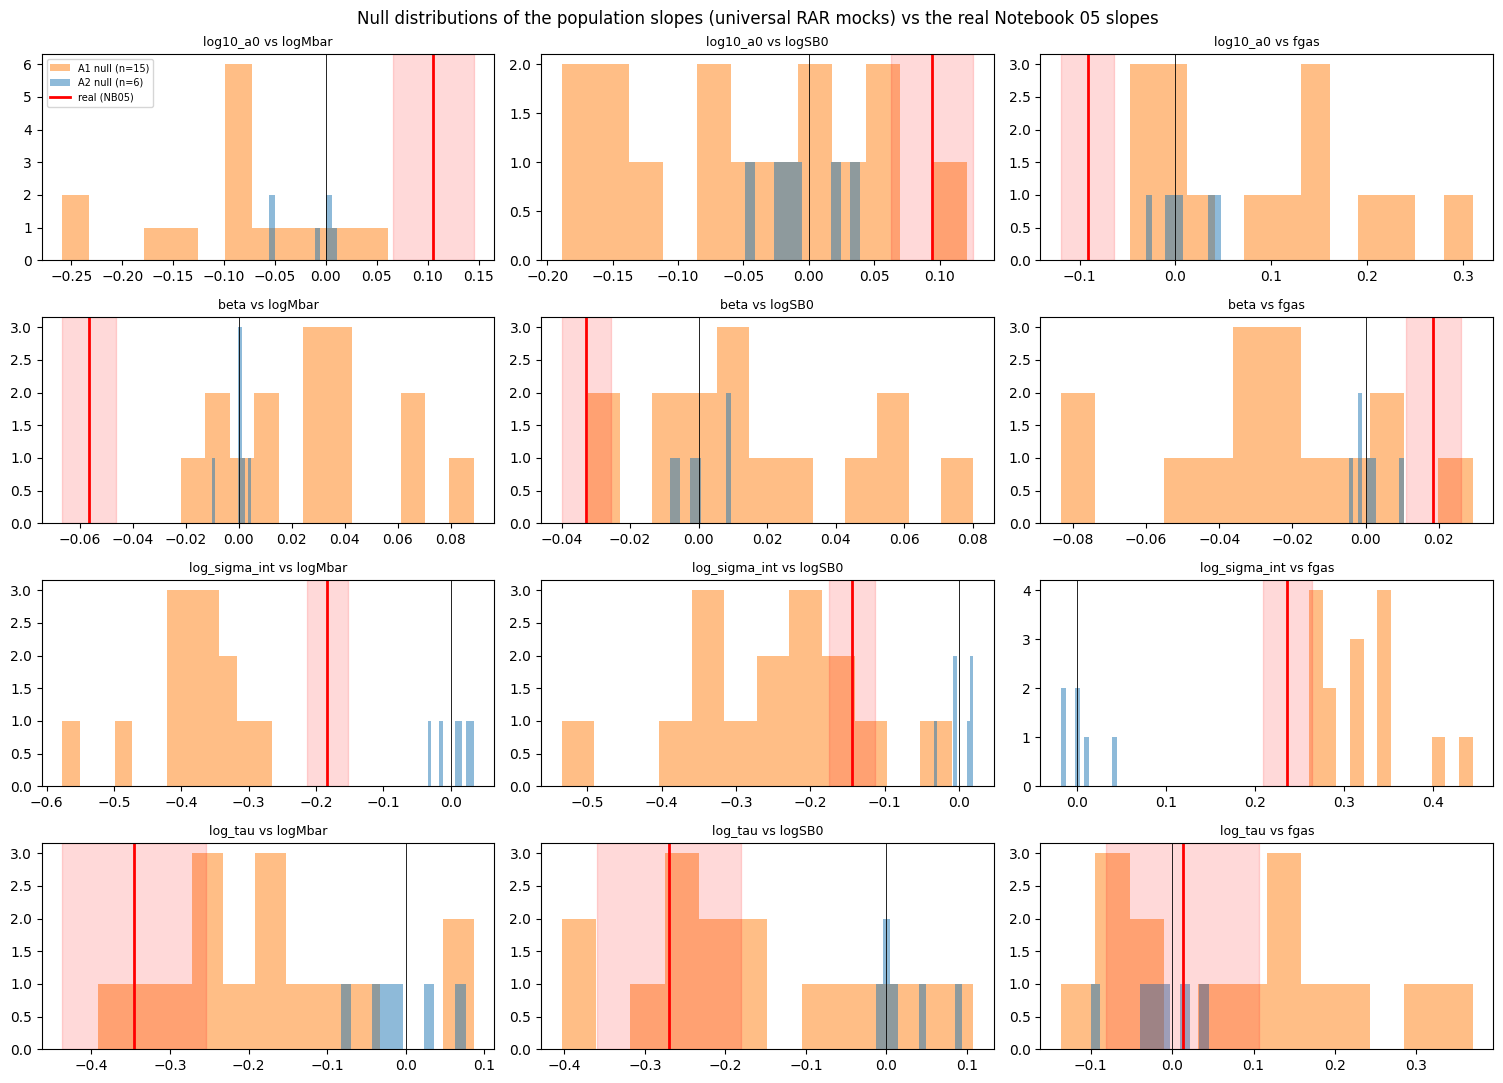

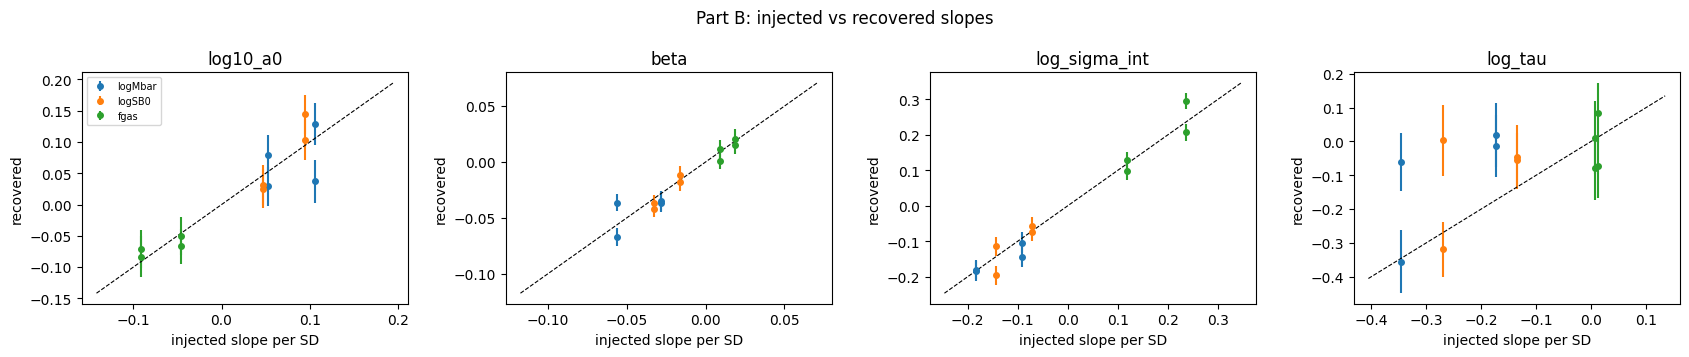

In [18]:
def savefig(fig, name):
    p = safe_path(OUT["figures"] / name); fig.savefig(p, dpi=130, bbox_inches="tight"); plt.show(); return p
if len(use):
    fig, ax = plt.subplots(len(POP_PARAMS), len(COVARIATES), figsize=(15, 11))
    for i, p in enumerate(POP_PARAMS):
        for j, c in enumerate(COVARIATES):
            a = ax[i, j]
            for scen, col in (("A1_null_correlated", "C1"), ("A2_null_white", "C0")):
                v = use[(use.scenario == scen) & (use.parameter == p) & (use.covariate == c)].slope_median
                if len(v): a.hist(v, bins=12, alpha=0.5, color=col, label=f"{scen.split('_')[0]} null (n={len(v)})")
            if (p, c) in REAL_SLOPE:
                rv, rsd = REAL_SLOPE[(p, c)]; a.axvline(rv, color="r", lw=2, label="real (NB05)"); a.axvspan(rv - rsd, rv + rsd, color="r", alpha=0.15)
            a.axvline(0, color="k", lw=0.6); a.set_title(f"{p} vs {c}", fontsize=9)
            if i == 0 and j == 0: a.legend(fontsize=7)
    fig.suptitle("Null distributions of the population slopes (universal RAR mocks) vs the real Notebook 05 slopes"); fig.tight_layout(); savefig(fig, "06_null_vs_real_slopes.png")
if len(rec):
    fig, ax = plt.subplots(1, len(POP_PARAMS), figsize=(17, 3.6))
    for a, p in zip(ax, POP_PARAMS):
        t = b[b.parameter == p]
        for c, col in zip(COVARIATES, ("C0", "C1", "C2")):
            tt = t[t.covariate == c]; a.errorbar(tt.injected_slope, tt.slope_median, yerr=tt.slope_sd, fmt="o", color=col, label=c, ms=4)
        lim = [min(t.injected_slope.min(), t.slope_median.min()) - 0.05, max(t.injected_slope.max(), t.slope_median.max()) + 0.05]
        a.plot(lim, lim, "k--", lw=0.8); a.set_xlabel("injected slope per SD"); a.set_ylabel("recovered"); a.set_title(p)
    ax[0].legend(fontsize=7); fig.suptitle("Part B: injected vs recovered slopes"); fig.tight_layout(); savefig(fig, "06_recovery.png")

## 12. Exports and Report

In [19]:
pd.DataFrame(CHECKS).to_csv(OUT["diagnostics"] / "06_integrity_checks.csv", index=False)
config = {"run_id": RUN_ID, "created_utc": RUN_TIMESTAMP, "versions": VERSIONS, "notebook03_run_id": RUN03, "notebook04_D_posterior": str(D_NC),
          "notebook05_slopes": str(runs5[-1]), "truth_A1_correlated": TRUTH_CORR, "truth_A2_B_white": TRUTH_WHITE,
          "A_i_ell_i": "per-galaxy posterior medians of full Model D (Notebook 04)", "corr_lnA_with_covariates": corrA,
          "plan": {"N_NULL_CORR": N_NULL_CORR, "N_NULL_WHITE": N_NULL_WHITE, "INJ_AMPLITUDES": INJ_AMPLITUDES, "N_INJ": N_INJ, "mock_seed": MOCK_SEED},
          "mock_fit": MOCK_FIT, "mock_usability": {"rhat_max": MOCK_RHAT_MAX, "ess_min": MOCK_ESS_MIN, "divergences": 0},
          "decision_rule": {"family": N_FAMILY, "per_test_alpha": ALPHA_P, "z_crit": ZCRIT}, "resume_from": RESUME_FROM}
(OUT["config"] / "06_injection_config.json").write_text(json.dumps(config, indent=2, default=str))
pd.DataFrame([{"package": k, "version": str(v)} for k, v in VERSIONS.items()]).to_csv(OUT["config"] / "06_package_versions.csv", index=False)
chk = pd.DataFrame(CHECKS)
def fmt_cal(df, scen):
    if df.empty or "scenario" not in df: return "* (no usable mocks)"
    d = df[df.scenario == scen]
    return "\n".join(f"* {r.parameter} vs {r.covariate}: real {r.real_slope:+.4f}; null {r.null_mean:+.4f} ± {r.null_sd:.4f}; noise-calibrated z = {r.noise_calibrated_z:+.2f}; "
                     f"empirical p {'<' if r.real_beyond_all_null_mocks else '='} {max(r.empirical_two_sided_p, r.p_floor):.3f} -> "
                     f"{'still supported' if r.still_supported_after_calibration else 'NOT supported after calibration'}" for r in d.itertuples()) or "* (no usable mocks)"
report = f"""# Notebook 06 — Injection–Recovery (Parts A and B) — Report

*Run {RUN_ID} ({RUN_TIMESTAMP} UTC). Notebook 03 run {RUN03}; Notebook 04 Model D posterior {D_NC.parents[1].name}; Notebook 05 run {runs5[-1].parents[1].name}. This file exists only if the notebook ran.*

## Setup
* Mocks: SPARC radii, errors, baryonic components and catalogue nuisances; true D, i, Upsilon* drawn from the model priors. Fitted with Notebook 05's model and decision rule (|z| > {ZCRIT:.2f}).
* A1 truth: full Model D posterior medians (per-galaxy A_i, l_i; tau {TRUTH_CORR['tau']:.4f}; sigma_int {TRUTH_CORR['sigma_int']:.4f}). Correlation of ln A_i with the covariates: {json.dumps({k: round(v, 2) for k, v in corrA.items()})}.
* A2/B truth: Notebook 03 Model C medians (sigma_int {TRUTH_WHITE['sigma_int']:.4f}, tau {TRUTH_WHITE['tau']:.4f}); no correlated noise.
* Mock fits: {MOCK_FIT['chains']} chains x ({MOCK_FIT['warmup']} + {MOCK_FIT['samples']}); usable if R-hat < {MOCK_RHAT_MAX}, ESS >= {MOCK_ESS_MIN} (slopes, intercepts), 0 divergences.
* Usable fractions: {summary_use.round(3).to_dict("records")}

## Part A — family-wise false-positive rate (nominal {FAMILY_ALPHA:.0%})
{chr(10).join(f"* {r.scenario}: {r.n_with_any_supported}/{r.n_mocks} mocks with >= 1 'supported' slope = {r.family_wise_rate:.2f} (95% {r.fw_95_low:.2f}-{r.fw_95_high:.2f})" for r in fw.itertuples())}

## Real Notebook 05 slopes against the correlated-noise null (A1) — the decisive comparison
{fmt_cal(cal, "A1_null_correlated")}

## Real slopes against the white-noise null (A2, calibration)
{fmt_cal(cal, "A2_null_white")}

## Part B — recovery
{chr(10).join(f"* {r.parameter} vs {r.covariate} at {r.amplitude:.1f}x: injected {r.injected:+.4f}, recovered {r.recovered_mean:+.4f}, bias {r.mean_bias_in_sd:+.2f} SD, coverage {r.coverage95:.2f}, power {r.power:.2f} (n={r.n})" for r in rec.itertuples()) if len(rec) else "* (no usable injection mocks)"}

## Interpretation rules (declared)
* A real slope is **robust to correlated noise** only if it stays beyond the Bonferroni threshold after calibration against the A1 null **and** lies beyond the bulk of the A1 null mocks.
* If the A1 null itself produces 'supported' slopes in the same direction, the Notebook 05 result for that slope is **explainable by galaxy-dependent correlated noise** and must not be reported as a physical dependence.
* With {N_NULL_CORR} A1 mocks the empirical p-value cannot go below {1 / (N_NULL_CORR + 1):.3f}; more mocks are needed for stronger statements (set RAR_N_NULL_CORR and resume).
* The A1 truth uses Model D medians, which had unconverged elements for one galaxy and for tau/mu_u (Notebook 04); A_i and l_i are therefore a realistic, not exact, noise model.
* Part C (identifiability of sigma_int vs correlated noise with GP fits) is not in this notebook.

## Checks
{len(chk)} checks: {int((chk.status == "FAIL").sum())} FAIL, {int((chk.status == "WARN").sum())} WARN.
"""
rep = OUT["tables"] / "06_Injection_Recovery_Report.md"; rep.write_text(report, encoding="utf-8")
manifest = pd.DataFrame([{"file": str(p.relative_to(OUT_ROOT)), "bytes": p.stat().st_size} for p in sorted(OUT_ROOT.rglob("*")) if p.is_file()])
manifest.to_csv(OUT["config"] / "06_output_manifest.csv", index=False)
print(report); print("Outputs:", OUT_ROOT)

# Notebook 06 — Injection–Recovery (Parts A and B) — Report

*Run 20261028T075632Z (2026-10-28T07:56:32Z UTC). Notebook 03 run 20261022T095735Z; Notebook 04 Model D posterior 20261026T083032Z; Notebook 05 run 20261027T161151Z. This file exists only if the notebook ran.*

## Setup
* Mocks: SPARC radii, errors, baryonic components and catalogue nuisances; true D, i, Upsilon* drawn from the model priors. Fitted with Notebook 05's model and decision rule (|z| > 2.87).
* A1 truth: full Model D posterior medians (per-galaxy A_i, l_i; tau 0.0476; sigma_int 0.0005). Correlation of ln A_i with the covariates: {"logMbar": 0.62, "logSB0": 0.42, "fgas": -0.47}.
* A2/B truth: Notebook 03 Model C medians (sigma_int 0.0356, tau 0.1220); no correlated noise.
* Mock fits: 2 chains x (500 + 750); usable if R-hat < 1.05, ESS >= 100.0 (slopes, intercepts), 0 divergences.
* Usable fractions: [{'scenario': 'A1_null_correlated', 'fits': 48, 'usable_fraction': 0.938}, {'scenario': 'A2_null_white', 'fits': 18,